# From Raw Spectrum to Metal Prediction — a walkthrough

# [] Run pip install ipykernel
# [] python -m ipykernel install --user --name=ir-spec --display-name "IR Spec (venv)"

This notebook illustrates **how the IR-spectra metal-ID pipeline works**, step by step:

1. A single molecule's raw (discrete) vibrational spectrum
2. Gaussian broadening onto a fixed wavenumber grid
3. Scaling up to many molecules → a joined dataset
4. The normalization recipe (L2 → drop low-variance → StandardScaler)
5. GroupKFold splitting (no conformation leakage)
6. Training the classifier (Gradient Boosting)
7. Reading the confusion matrix
8. Feature importance which wavenumbers actually drive the prediction

> **This notebook uses small, synthetic, illustrative data  not the real
> 10,861-row experimental dataset.** The peak positions and intensities
> below are made up to be *chemically plausible* and to reproduce the same
> qualitative story as the real project (Co↔Ni confusion, signal
> concentrated in 3 coordination-sensitive regions), purely because that's
> how the synthetic generator was designed. For real results, run
> `vibspectrum_parser.py` -> `gradient_boosting_metal.py` on the actual
> Nova-generated data and the run the `linear_curve.py` to examine the success of the model.


## Step 1: a single molecule's raw spectrum

Quantum chemistry codes (NWChem, xTB) don't hand you a smooth curve they
hand you a **stick spectrum**: a list of discrete vibrational modes, each
with a frequency (cm⁻¹) and an intensity. Below is one illustrative
molecule: a cobalt–amino-acid complex, with peaks placed in the three
regions that turn out to matter later. This is done so that the features have more empahsis for the models to train on.

- **~300–600 cm⁻¹** —> metal–ligand stretch (coordination-sensitive)
- **~1400–1600 cm⁻¹** —> carboxylate / amide bands
- **~3300–3600 cm⁻¹** —> O–H / N–H stretch


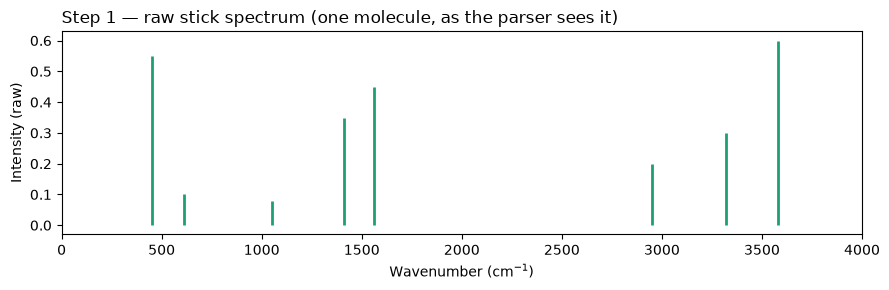

8 discrete vibrational modes parsed for this molecule.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

# A single illustrative "stick" spectrum: (frequency, intensity) pairs.
# This is what a parsed NWChem/xTB output effectively gives you per molecule.
#instead of this you would be feeding in the CSV of your parsed data
example_peaks = np.array([
    [ 450, 0.55],   # metal-ligand stretch (Co-O/N coordination)
    [ 610, 0.10],
    [1050, 0.08],   # C-C / C-N backbone
    [1410, 0.35],   # carboxylate symmetric stretch
    [1560, 0.45],   # carboxylate asymmetric stretch
    [2950, 0.20],   # aliphatic C-H stretch
    [3320, 0.30],   # N-H stretch
    [3580, 0.60],   # O-H stretch
]) 

#way more intensities are present in the real dataset

fig, ax = plt.subplots(figsize=(9, 3))
ax.vlines(example_peaks[:, 0], 0, example_peaks[:, 1], color="#1D9E75", linewidth=2)
ax.set_xlabel("Wavenumber (cm$^{-1}$)")
ax.set_ylabel("Intensity (raw)")
ax.set_title("Step 1 — raw stick spectrum (one molecule, as the parser sees it)", loc="left")
ax.set_xlim(0, 4000)
plt.tight_layout()
plt.show()

print(f"{len(example_peaks)} discrete vibrational modes parsed for this molecule.")


## Step 2: Gaussian broadening onto a fixed grid

A stick spectrum can't be fed to a classifier directly  different
molecules have different *numbers* of modes, at different frequencies, so
there's no fixed feature vector yet.

The fix (matching the real pipeline): convolve each stick with a narrow
Gaussian and evaluate the result on a **fixed grid, 50–4000 cm⁻¹, step 5
→ 791 bins**. Every molecule, no matter how many raw modes it has, becomes
the same 791-length vector.


Grid: 791 bins from 50 to 4000 cm^-1, step 5


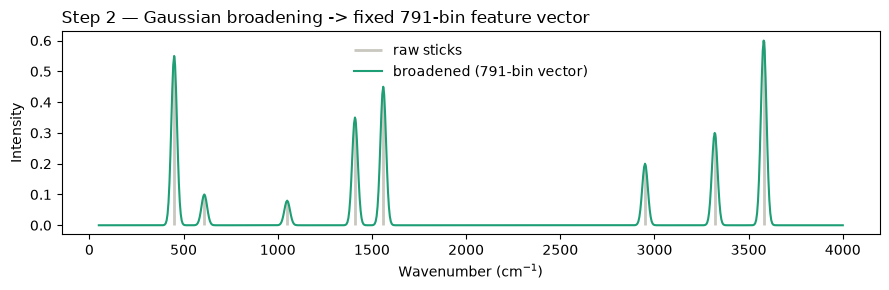

This molecule is now a single vector of length 791.


In [2]:
GRID_MIN, GRID_MAX, GRID_STEP = 50, 4000, 5
grid = np.arange(GRID_MIN, GRID_MAX + GRID_STEP, GRID_STEP)  # 791 bins
print(f"Grid: {len(grid)} bins from {grid[0]} to {grid[-1]} cm^-1, step {GRID_STEP}")

def gaussian_broaden(peaks, grid, sigma=15.0):
    """peaks: (N,2) array of [frequency, intensity]. Returns intensity on `grid`."""
    freqs, intens = peaks[:, 0], peaks[:, 1]
    # shape (n_grid, n_peaks) -> sum contributions
    diff = grid[:, None] - freqs[None, :]
    gauss = np.exp(-0.5 * (diff / sigma) ** 2)
    return (gauss * intens[None, :]).sum(axis=1)

broadened = gaussian_broaden(example_peaks, grid, sigma=15.0)

fig, ax = plt.subplots(figsize=(9, 3))
ax.vlines(example_peaks[:, 0], 0, example_peaks[:, 1], color="#c9c7bf", linewidth=2, label="raw sticks")
ax.plot(grid, broadened, color="#1D9E75", linewidth=1.5, label="broadened (791-bin vector)")
ax.set_xlabel("Wavenumber (cm$^{-1}$)")
ax.set_ylabel("Intensity")
ax.set_title("Step 2 — Gaussian broadening -> fixed 791-bin feature vector", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"This molecule is now a single vector of length {len(broadened)}.")


## Step 3: scaling up: many molecules → a dataset

Every molecule goes through Step 1 → Step 2 the same way. Stack the
resulting 791-length vectors into rows of a table, alongside their
labels (`amino_acid`, `metal`, `conformation`) — this is the shape of
`vibspectrum_broadened.csv`.

Below, a small synthetic generator builds spectra for **4 metals** (mirroring
Co/Cu/Ni/Zn), **5 amino acids**, and **6 conformations each** — a tiny stand-in
for the real ~10,861-row dataset. The metal–ligand peak position is
deliberately set close together for Co and Ni (mirroring their similar
coordination chemistry) and further apart for Cu and Zn.


In [3]:
metals = {
    "Co+2": {"ml_peak": 450, "ml_height": 0.55},
    "Ni+2": {"ml_peak": 465, "ml_height": 0.50},   # close to Co -> expect confusion
    "Cu+2": {"ml_peak": 520, "ml_height": 0.65},   # distinct (Jahn-Teller-ish shift)
    "Zn+2": {"ml_peak": 380, "ml_height": 0.60},   # distinct
}
amino_acids = ["AH", "AR", "GL", "SE", "VA"]
n_conformations = 6

def make_molecule_spectrum(metal_params, rng):
    """Build one molecule's stick spectrum with a bit of random jitter."""
    peaks = np.array([
        [metal_params["ml_peak"] + rng.normal(0, 6), metal_params["ml_height"] + rng.normal(0, 0.03)],
        [1410 + rng.normal(0, 5), 0.35 + rng.normal(0, 0.03)],
        [1560 + rng.normal(0, 5), 0.45 + rng.normal(0, 0.03)],
        [2950 + rng.normal(0, 8), 0.20 + rng.normal(0, 0.03)],
        [3320 + rng.normal(0, 8), 0.30 + rng.normal(0, 0.03)],
        [3580 + rng.normal(0, 8), 0.60 + rng.normal(0, 0.03)],
    ])
    return peaks

rows = []
for aa in amino_acids:
    for metal, params in metals.items():
        for conf in range(n_conformations):
            peaks = make_molecule_spectrum(params, rng)
            spectrum = gaussian_broaden(peaks, grid, sigma=15.0)
            spectrum += rng.normal(0, 0.01, size=spectrum.shape)  # measurement-style noise
            rows.append({
                "amino_acid": aa, "metal": metal, "conformation": conf,
                **{f"spec_{int(w)}": v for w, v in zip(grid, spectrum)}
            })

df = pd.DataFrame(rows)
print(f"Synthetic dataset: {len(df)} rows, {df['metal'].nunique()} metals, "
      f"{df['amino_acid'].nunique()} amino acids, {n_conformations} conformations each.")
df[["amino_acid", "metal", "conformation"]].head()


Synthetic dataset: 120 rows, 4 metals, 5 amino acids, 6 conformations each.


,amino_acid,metal,conformation
0,AH,Co+2,0
1,AH,Co+2,1
2,AH,Co+2,2
3,AH,Co+2,3
4,AH,Co+2,4


## Step 4: normalization 

The locked recipe, in order:

1. **Per-spectrum L2 normalize** (each molecule's vector scaled to unit length)
2. **Drop low-variance bins** (uninformative flat regions)
3. **StandardScaler** (zero mean, unit variance per bin)
4. **Guard non-finite values**

Steps 2–3 are *fit* on the training split only and applied to test never
the reverse, or test information leaks into the model.


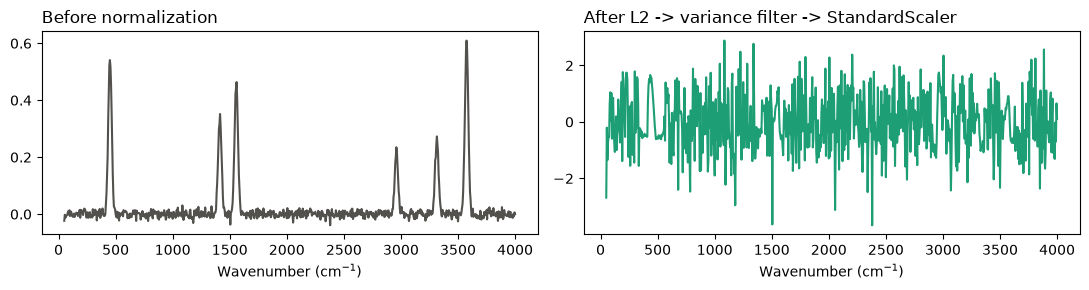

In [4]:
from sklearn.preprocessing import StandardScaler, normalize

spec_cols = [c for c in df.columns if c.startswith("spec_")]

def normalize_features_fit(X_train, X_test, var_threshold=1e-8):
    X_train = normalize(X_train, norm="l2", axis=1)
    X_test = normalize(X_test, norm="l2", axis=1)

    std = X_train.std(axis=0)
    keep = std > max(1e-8, var_threshold)
    X_train, X_test = X_train[:, keep], X_test[:, keep]

    scaler = StandardScaler().fit(X_train)
    X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

    X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
    X_test = np.nan_to_num(X_test, nan=0.0, posinf=0.0, neginf=0.0)
    return X_train, X_test, keep

# quick illustration on a 70/30 split (real CV split happens in Step 5)
X_all = df[spec_cols].to_numpy()
split = int(len(df) * 0.7)
X_tr_demo, X_te_demo, _ = normalize_features_fit(X_all[:split], X_all[split:])

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(grid, X_all[0], color="#52514e")
axes[0].set_title("Before normalization", loc="left")
axes[1].plot(grid[: X_tr_demo.shape[1]], X_tr_demo[0], color="#1D9E75")
axes[1].set_title("After L2 -> variance filter -> StandardScaler", loc="left")
for ax in axes:
    ax.set_xlabel("Wavenumber (cm$^{-1}$)")
plt.tight_layout()
plt.show()


## Step 5: GroupKFold: no conformation leakage

All conformations of the **same molecule** (`amino_acid + metal`) must stay
on the same side of any train/test split. A random split would let the
model "cheat" by seeing near-duplicate conformations of a test molecule
during training this is to prevent inflating the prediction score.


In [5]:
from sklearn.model_selection import GroupKFold

df["group_id"] = df["amino_acid"] + "_" + df["metal"]
groups = df["group_id"].to_numpy()
y = df["metal"].to_numpy()

print(f"{df['group_id'].nunique()} unique groups (amino_acid x metal combos).")
print("Example groups:", sorted(df['group_id'].unique())[:5])

gkf = GroupKFold(n_splits=5)
fold_sizes = [(len(tr), len(te)) for tr, te in gkf.split(X_all, y, groups)]
print("Fold (train, test) sizes:", fold_sizes)


20 unique groups (amino_acid x metal combos).
Example groups: ['AH_Co+2', 'AH_Cu+2', 'AH_Ni+2', 'AH_Zn+2', 'AR_Co+2']
Fold (train, test) sizes: [(96, 24), (96, 24), (96, 24), (96, 24), (96, 24)]


## Step 6: train the classifier

`HistGradientBoostingClassifier` is the chosen model in the real project
(beat Random Forest and a linear LDA baseline). Predictions here are
collected out-of-fold via `cross_val_predict`, so every prediction comes
from a model that never saw that molecule's group during training.


In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score, confusion_matrix

# Manual per-fold loop so normalization is refit on train only each fold
# (cross_val_predict alone can't do fold-specific preprocessing cleanly).
oof_pred = np.empty(len(df), dtype=object)

for train_idx, test_idx in gkf.split(X_all, y, groups):
    X_tr, X_te, _ = normalize_features_fit(X_all[train_idx], X_all[test_idx])
    clf = HistGradientBoostingClassifier(random_state=0)
    clf.fit(X_tr, y[train_idx])
    oof_pred[test_idx] = clf.predict(X_te)

bal_acc = balanced_accuracy_score(y, oof_pred)
print(f"Balanced accuracy (synthetic demo data): {bal_acc:.3f}")
print(f"(Real project, real 10,861-row dataset: 0.894 with these same steps.)")


Balanced accuracy (synthetic demo data): 0.900
(Real project, real 10,861-row dataset: 0.894 with these same steps.)


## Step 7: reading the confusion matrix

Row-normalized: each row sums to 1.0, so the diagonal is per-class recall.
Because Co and Ni were built with nearby metal-ligand peaks (Step 3), watch
for them to bleed into each other here — same qualitative pattern as the
real 13%/9% Co↔Ni cross-confusion.


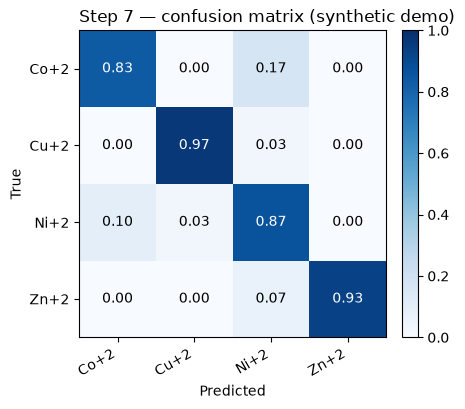

In [ ]:
labels = sorted(df["metal"].unique())
cm = confusion_matrix(y, oof_pred, labels=labels).astype(float)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Step 7 — confusion matrix (synthetic demo)", loc="left")
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_norm[i, j] > 0.5 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


## Step 8: feature importance: which wavenumbers matter

Permutation importance shuffles one feature at a time and measures how
much accuracy drops. If the pipeline is working as intended, importance
should concentrate in the regions we deliberately built signal into: the
metal–ligand stretch, the carboxylate/amide bands, and the O–H/N–H
stretch — the same three regions the real project's importance analysis
identified.


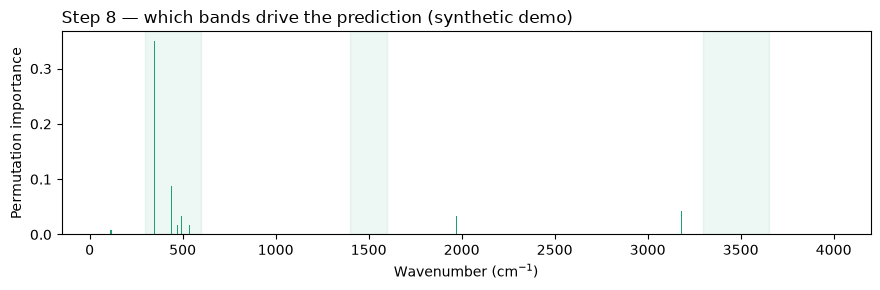

In [8]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupShuffleSplit

tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=0).split(X_all, y, groups))
X_tr, X_te, keep_mask = normalize_features_fit(X_all[tr], X_all[te])
clf = HistGradientBoostingClassifier(random_state=0).fit(X_tr, y[tr])

perm = permutation_importance(clf, X_te, y[te], n_repeats=5, random_state=0,
                               scoring="balanced_accuracy", n_jobs=-1)
grid_kept = grid[keep_mask]

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(grid_kept, perm.importances_mean, width=6, color="#1D9E75")
ax.set_xlabel("Wavenumber (cm$^{-1}$)")
ax.set_ylabel("Permutation importance")
ax.set_title("Step 8 — which bands drive the prediction (synthetic demo)", loc="left")
for lo, hi, name in [(300, 600, "M-L stretch"), (1400, 1600, "carboxylate/amide"), (3300, 3650, "O-H/N-H stretch")]:
    ax.axvspan(lo, hi, color="#1D9E75", alpha=0.08)
plt.tight_layout()
plt.show()


## Recap

| Step | What happens | Real-project script |
|---|---|---|
| 1 | Raw stick spectrum (frequency, intensity) per molecule | `vibspectrum_parser.py`, `xtb_parser.py` |
| 2 | Gaussian broadening onto fixed 791-bin grid | broadening module |
| 3 | Stack molecules into a joined, labeled dataset | incremental join-ready pipeline (Nova) |
| 4 | L2 → drop low-variance → StandardScaler (fit train-only) | `normalize_features()` |
| 5 | GroupKFold by `amino_acid + metal` | prevents conformation leakage |
| 6 | Train `HistGradientBoostingClassifier` | `gradient_boosting_metal.py` |
| 7 | Row-normalized confusion matrix | `gb_confusion.png` |
| 8 | Permutation importance over wavenumbers | `gb_importance.png` |

On the real 10,861-row dataset this pipeline gets **0.894 balanced
accuracy**, with **Zn (0.95) and Cu (0.93) cleanest** and **Co↔Ni
(0.83/0.86) as the persistent confusion pair** — consistent with their
similar first-row transition-metal coordination chemistry. The learning-
curve study (`learning_curve.py`) builds on this same pipeline to answer a
different question: how much data a *new* metal needs before the model
recognizes it.
